# 2 Prognostics

Stage 2 of the paper: the RUL prediction of the failing component with the 15 networks and the Constant baseline. Everything is computed from the stored results in `results/stage2/` (see notebook 0). Only Fig. 7 reads the CARE-to-Compare dataset in `data/`.

Figures that appear in the paper are marked **Paper**. The others are extra and not in the paper. Figures are written to `outputs/2_prognostics/`, in `paper/` and `extra/`.

With `RESULTS = 'retrained'`, the notebook reads the results of notebook 0 in `results_retrained/` instead, and writes its figures to `outputs_retrained/`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd

from two_stage import config as cfg, evaluation as ev, plots, stage2

RESULTS = 'paper'

cfg.use_results(RESULTS)
pd.set_option('display.precision', 2)
PAPER = cfg.figure_dir('2_prognostics') / 'paper'
EXTRA = cfg.figure_dir('2_prognostics') / 'extra'

tuned = ev.load_tuned()
results = ev.load_case_results()

## Tuned configurations

Bin size, window length and number of epochs of every model, and its validation CRPS on Case 1.

In [2]:
pd.DataFrame(tuned).T[['resample_freq', 'window_days', 'window', 'epochs', 'score']]

,resample_freq,window_days,window,epochs,score
lstm+none,1h,28.0,672,19,5.22
lstm+embed,1h,7.0,168,13,5.54
lstm+head_linear,24h,28.0,28,17,6.46
lstm+head_mlp,24h,28.0,28,11,5.93
lstm+separate,8h,28.0,84,21,6.05
cnn+none,1h,28.0,672,22,6.01
cnn+embed,1h,28.0,672,8,5.36
cnn+head_linear,1h,14.0,336,1,4.47
cnn+head_mlp,1h,28.0,672,15,3.5
cnn+separate,8h,14.0,42,8,6.31


## Constant baseline

**Paper, Fig. 7.** The labels of the four training failures of Case 5 and the Constant baseline, the mean of all training labels.

,event,name,component,max_label,min_label,windows
2,19,T3,transformer,20.65,0.17,63
0,34,T1,transformer,20.98,0.17,66
1,53,B1,bearing,39.52,0.01,127
3,77,B3,bearing,56.08,0.07,185


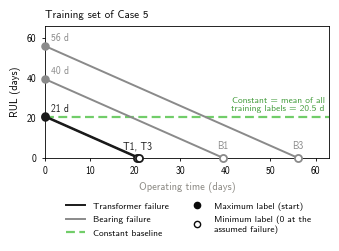

In [3]:
labels, constant = stage2.training_labels(5, tuned['constant'])
fig = plots.constant_baseline(labels, constant)
plots.save(fig, PAPER / 'fig07_constant_baseline', tight=False)
labels

## Overall results

Cases 5, 6, 8 and 9 are independent of the tuning. Per case, the two held-out failures are pooled by their number of windows, and the five repeats are averaged.

**Paper, Fig. 12.**

,mae,r2,crps,cov95,width95,RS_total,RS_under
model,,,,,,,
cnn+embed,16.37,-2.69,14.70,0.24,12.59,0.40,0.40
lstm+embed,13.53,-0.45,10.90,0.46,23.82,0.26,0.26
cnn_lstm+embed,12.08,-0.03,9.60,0.51,23.29,0.29,0.27
cnn+head_linear,13.21,-0.28,10.84,0.45,23.30,0.32,0.31
lstm+head_linear,12.12,-0.10,9.97,0.52,20.40,0.30,0.30
cnn_lstm+head_linear,13.21,-0.38,10.32,0.49,25.29,0.30,0.30
cnn+head_mlp,13.18,-0.27,11.34,0.31,14.81,0.38,0.38
lstm+head_mlp,12.64,-0.25,10.47,0.47,19.97,0.30,0.30
cnn_lstm+head_mlp,13.36,-0.33,10.30,0.48,25.49,0.29,0.29


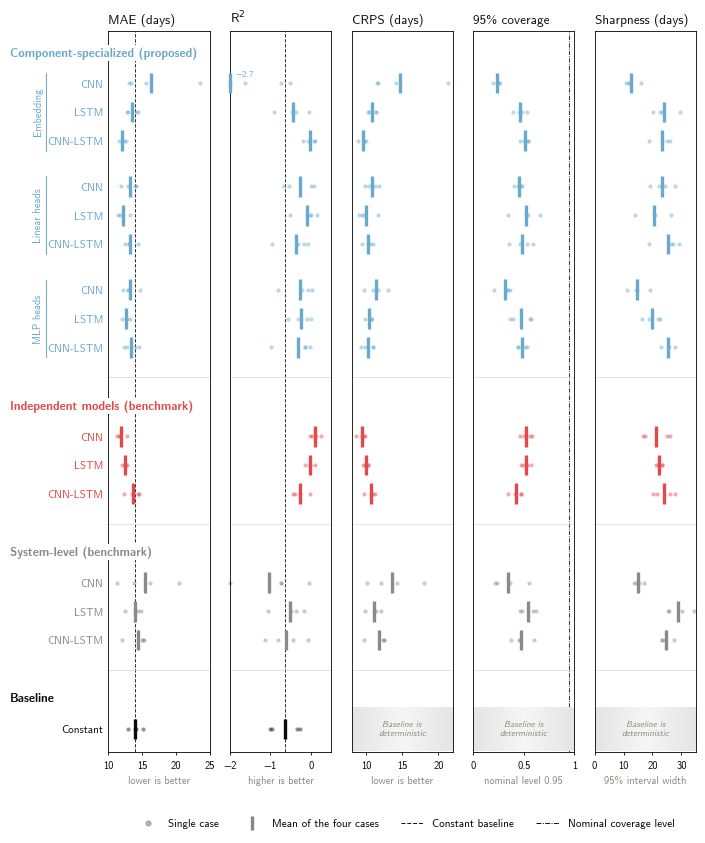

In [4]:
scores = ev.case_scores(results)
fig = plots.summary(scores)
plots.save(fig, PAPER / 'fig12_summary', tight=False)
means = ev.model_means(scores)
means

In [5]:
networks = means.drop('constant')
print(f"networks with a lower MAE than the Constant baseline: {(networks['mae'] < means.loc['constant', 'mae']).sum()} of {len(networks)}")
print(f"95% coverage of the networks: {networks['cov95'].min():.2f} to {networks['cov95'].max():.2f}")
print(f"share of the reliability score from intervals that are too narrow: {(networks['RS_under'] / networks['RS_total']).min():.0%} or more")

networks with a lower MAE than the Constant baseline: 12 of 15
95% coverage of the networks: 0.24 to 0.54
share of the reliability score from intervals that are too narrow: 94% or more


Paired t-tests on the MAE of the four independent cases, first against the Constant baseline, then for the three questions of the methodology.

In [6]:
against_constant = ev.t_tests_against_constant(scores)
print(f"significant among the networks that beat the Constant baseline: {against_constant[against_constant['better']]['significant'].sum()}")
against_constant

significant among the networks that beat the Constant baseline: 4


,model,mae,constant,better,t,p,significant
0,cnn+embed,16.37,13.98,False,1.16,0.33,False
1,lstm+embed,13.53,13.98,True,-0.78,0.49,False
2,cnn_lstm+embed,12.08,13.98,True,-3.55,0.04,True
3,cnn+head_linear,13.21,13.98,True,-3.07,0.05,False
4,lstm+head_linear,12.12,13.98,True,-3.29,0.05,True
5,cnn_lstm+head_linear,13.21,13.98,True,-1.08,0.36,False
6,cnn+head_mlp,13.18,13.98,True,-2.02,0.14,False
7,lstm+head_mlp,12.64,13.98,True,-3.42,0.04,True
8,cnn_lstm+head_mlp,13.36,13.98,True,-1.41,0.25,False
9,cnn+separate,11.80,13.98,True,-2.87,0.06,False


In [7]:
tests = ev.t_tests(scores)
display(tests.groupby('question', sort=False)['significant'].agg(['sum', 'count']))
tests[tests['significant']]

,sum,count
question,,
Component information,2,12
Component-specific parts,0,18
Backbone,3,15


,question,model_a,model_b,mae_a,mae_b,difference,t,p,significant
13,Component information,lstm+separate,lstm+none,12.39,13.89,-1.50,-3.81,3.19e-02,True
20,Component information,cnn_lstm+embed,cnn_lstm+none,12.08,14.34,-2.26,-3.58,3.74e-02,True
32,Backbone,lstm+embed,cnn_lstm+embed,13.53,12.08,1.45,6.37,7.83e-03,True
35,Backbone,lstm+head_linear,cnn_lstm+head_linear,12.12,13.21,-1.09,-3.82,3.17e-02,True
40,Backbone,cnn+separate,cnn_lstm+separate,11.80,13.70,-1.89,-5.21,1.37e-02,True


## Monte Carlo dropout settings

Passes per network: the CRPS and coverage at 100 passes against 1,000 passes, on Case 1.

largest change in CRPS: 0.94%, in 95% coverage: 0.045


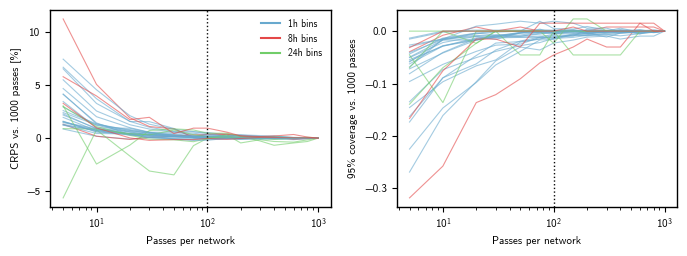

In [8]:
passes = ev.load_passes()
at_100 = ev.passes_at(passes)
print(f"largest change in CRPS: {at_100['crps_change_pct'].abs().max():.2f}%, in 95% coverage: {at_100['cov95_change'].abs().max():.3f}")
fig = plots.passes_curves(passes)
plots.save(fig, EXTRA / 'mc_passes_per_network')

Networks per ensemble, on the independent cases.

95% coverage with 15 networks: at most 0.73
most accurate with 15 networks: ['cnn+separate', 'cnn_lstm+embed', 'cnn_lstm+head_mlp', 'lstm+head_linear', 'lstm+separate']
most accurate with 3 networks:  ['cnn+separate', 'cnn_lstm+embed', 'cnn_lstm+head_mlp', 'lstm+head_linear', 'lstm+separate']


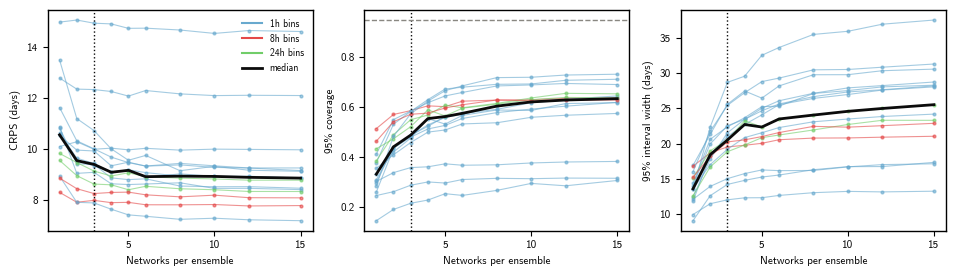

In [9]:
ensemble = ev.load_ensemble_size()
by_size = ev.ensemble_size_summary(ensemble[ensemble['case'].isin(ev.INDEPENDENT_CASES)])
largest = by_size.xs(15, level='networks')
print(f"95% coverage with 15 networks: at most {largest['cov95'].max():.2f}")
print('most accurate with 15 networks:', sorted(largest['crps'].nsmallest(5).index))
print('most accurate with 3 networks: ', sorted(means.drop('constant')['crps'].nsmallest(5).index))
fig = plots.ensemble_curves(by_size, {m: tuned[m]['resample_freq'] for m in stage2.NETWORKS})
plots.save(fig, EXTRA / 'mc_networks_per_ensemble')

## Leaking cases

Cases 2, 3, 4 and 7 share a held-out failure with the tuning case. The MAE of every model on these cases and on the independent cases, relative to the Constant baseline.

In [10]:
leak = ev.leak_comparison(results)
nets = leak.drop('constant')
print(f"further ahead of the Constant baseline on the leaking cases: {(nets['leaking_vs_constant'] < nets['independent_vs_constant']).sum()} of {len(nets)}")
print(f"less accurate than the Constant baseline: {(nets['leaking_vs_constant'] > 0).sum()} on the leaking cases, "
      f"{(nets['independent_vs_constant'] > 0).sum()} on the independent cases")
leak.sort_values('independent')

further ahead of the Constant baseline on the leaking cases: 14 of 15
less accurate than the Constant baseline: 1 on the leaking cases, 3 on the independent cases


,independent,independent_vs_constant,leaking,leaking_vs_constant,rank_independent,rank_leaking
model,,,,,,
cnn+separate,11.80,-2.18,9.88,-2.87,1.0,1.0
cnn_lstm+embed,12.08,-1.90,10.45,-2.31,2.0,2.0
lstm+head_linear,12.12,-1.86,10.81,-1.94,3.0,6.0
lstm+separate,12.39,-1.59,11.43,-1.33,4.0,9.0
lstm+head_mlp,12.64,-1.34,11.07,-1.69,5.0,7.0
cnn+head_mlp,13.18,-0.80,10.70,-2.06,6.0,4.0
cnn+head_linear,13.21,-0.78,11.53,-1.23,7.0,10.0
cnn_lstm+head_linear,13.21,-0.77,10.69,-2.07,8.0,3.0
cnn_lstm+head_mlp,13.36,-0.62,11.97,-0.78,9.0,11.0


Extra: the summary figure on the leaking cases.

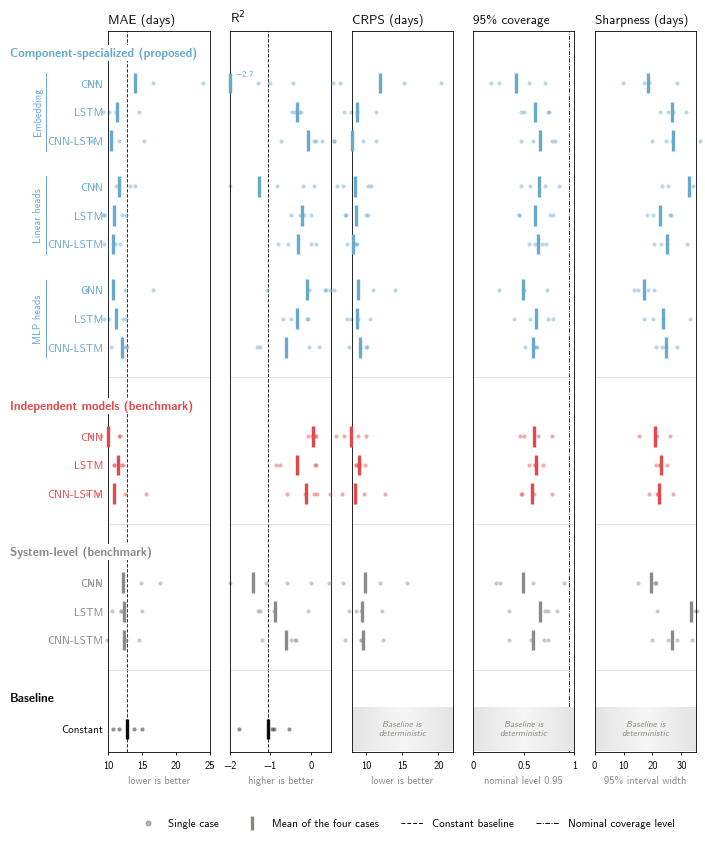

In [11]:
fig = plots.summary(ev.case_scores(results, ev.LEAKING_CASES))
plots.save(fig, EXTRA / 'summary_leaking_cases', tight=False)

## Detailed evaluation on Case 5

The most accurate model of each group by mean CRPS, and the independent case on which their MAE lies closest to its mean over the four cases.

In [12]:
chosen = ev.select_models(scores)
print({group: ev.display_name(model) for group, model in chosen.items()})
print('typical case:', ev.typical_case(scores, list(chosen.values()) + ['constant']))

{'specialized': 'CNN-LSTM with embedding', 'independent': 'Independent CNN models', 'system': 'System-level LSTM'}
typical case: 5


**Paper, Fig. 13.** All models on the two held-out failures of Case 5.

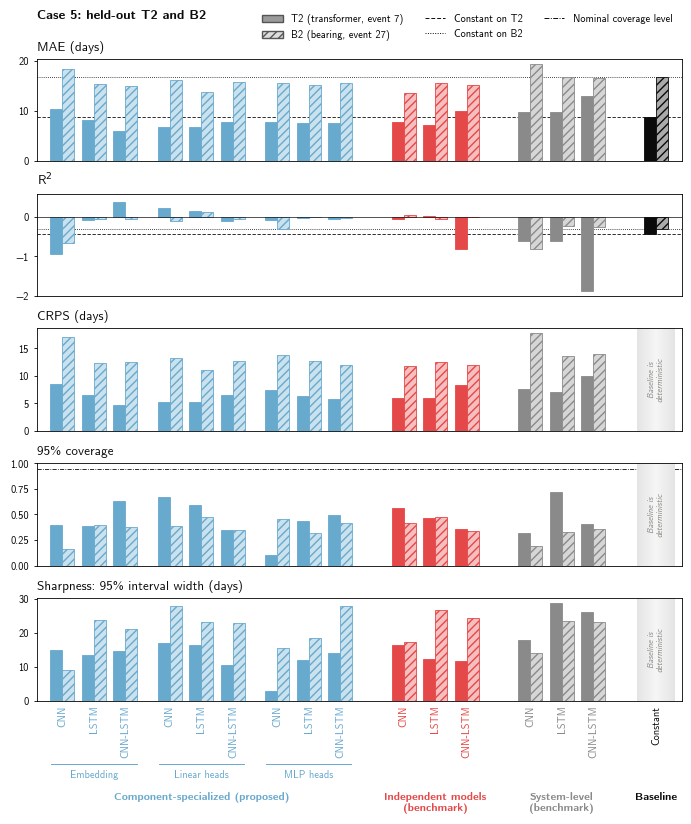

In [13]:
failure_scores = ev.failure_scores(results)
fig = plots.case_bars(failure_scores, 5)
plots.save(fig, PAPER / 'fig13_case5', dpi=200, tight=False)

**Paper, Fig. 14.** Predictions of the selected models on Case 5, from the rerun with the seeds of their median repeat.

mae   crps    r2
model          held_out                    
cnn+separate   False      4.10   3.19  0.72
               True      10.61   8.75  0.05
cnn_lstm+embed False      1.05   1.12  0.97
               True      11.24   8.93  0.13
constant       False     11.32   7.45 -1.39
               True      12.79   9.00 -0.36
lstm+none      False      1.20   1.06  0.97
               True      13.82  11.13 -0.39

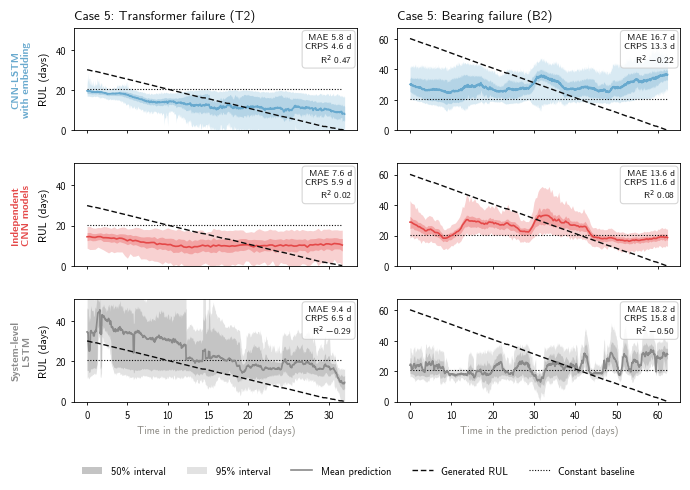

In [14]:
arrays = dict(np.load(cfg.result_path('stage2', 'case5_predictions.npz')))
case5 = pd.read_csv(cfg.result_path('stage2', 'case5_scores.csv'))
fig = plots.case_predictions(arrays, case5, chosen)
plots.save(fig, PAPER / 'fig14_case5_predictions', tight=False)
case5.groupby(['model', 'held_out'])[['mae', 'crps', 'r2']].mean()

## Per component and per case

**Paper, Figs. 15 and 16.** The summary for the transformer and the bearing failures separately.

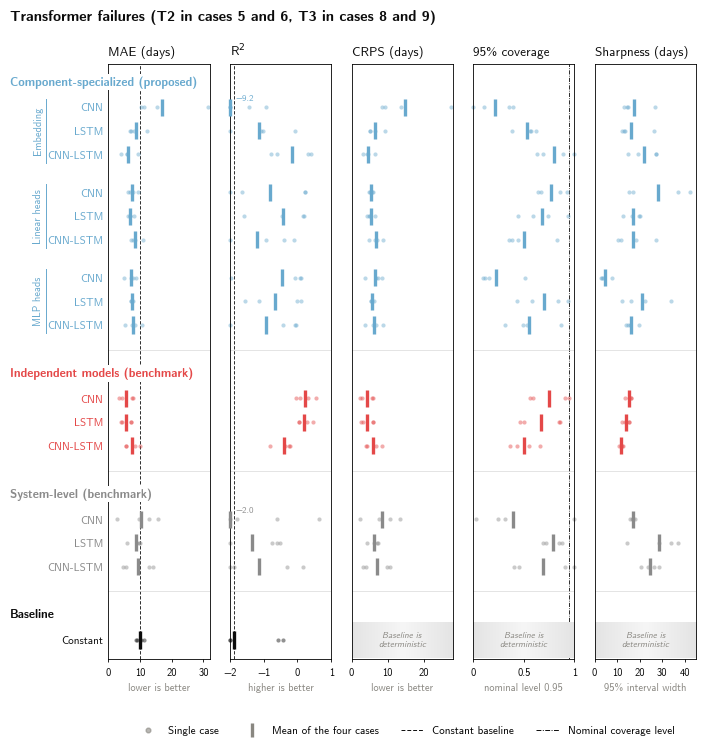

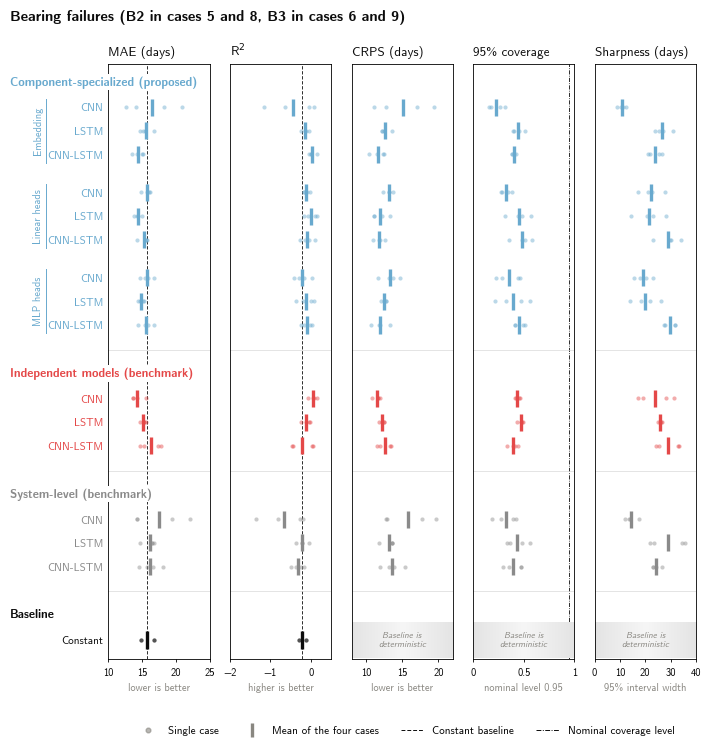

In [15]:
for number, component in ((15, 'transformer'), (16, 'bearing')):
    fig = plots.component_summary(failure_scores, component)
    plots.save(fig, PAPER / f'fig{number}_{component}_failures', tight=False)

**Paper, Figs. 17 to 19.** All models on Cases 6, 8 and 9.

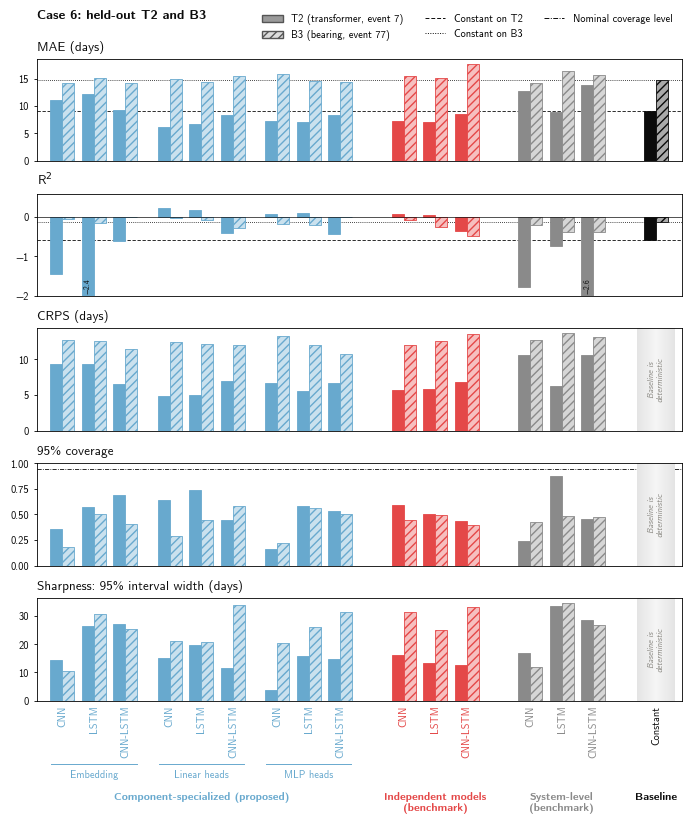

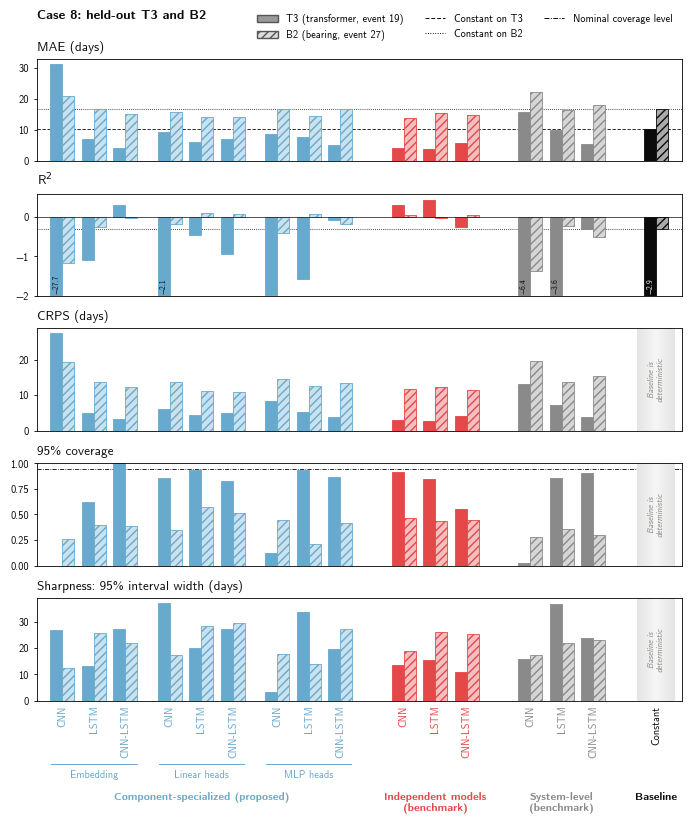

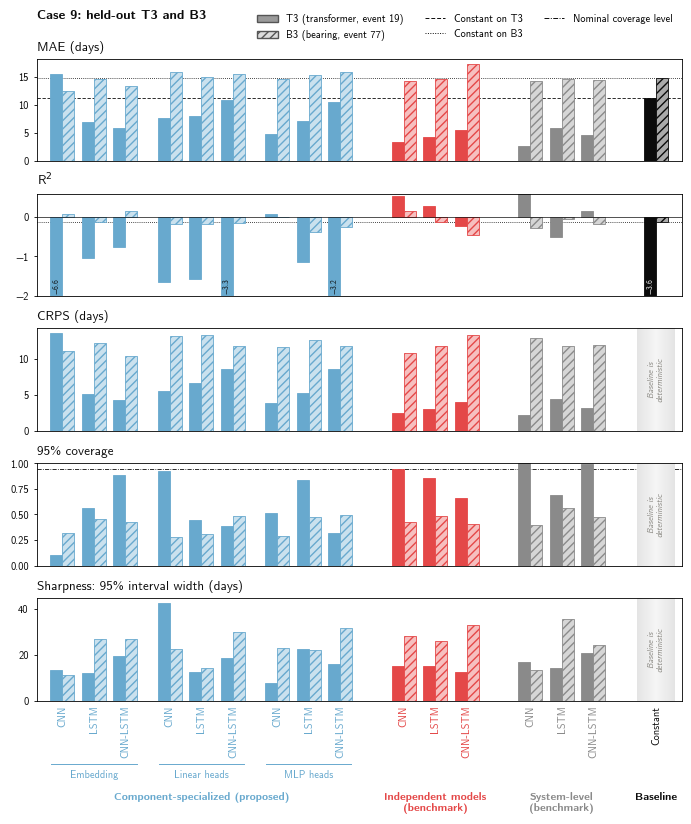

In [16]:
for number, case in ((17, 6), (18, 8), (19, 9)):
    fig = plots.case_bars(failure_scores, case)
    plots.save(fig, PAPER / f'fig{number}_case{case}', dpi=200, tight=False)